# Lab Assignment 04: Image Denoising Using Autoencoders
### Deep Learning Laboratory | Comprehensive Experimental Study on MNIST

**Student/Author:** Deep Learning Research Team  
**Dataset:** MNIST Handwritten Digits ($28 \times 28$ Grayscale, 70,000 Total Images)  
**Frameworks:** TensorFlow 2.x / Keras 3.x, NumPy, Matplotlib, Scikit-Image, Scikit-Learn  

---

## 1. Aim and Learning Objectives
### 1.1 Aim
To implement, evaluate, and systematically benchmark different types of autoencoders for image denoising using the MNIST handwritten digit dataset, and to study the effect of model architecture, latent representation, and noise level on reconstruction quality.

### 1.2 Learning Objectives
1. **Architecture Mastery:** Understand the non-linear encoder–latent space–decoder mapping that underpins representation learning.
2. **Noise Modeling:** Generate controlled Gaussian noise callsets across varying severity factors ($\sigma \in [0.1, 0.5]$).
3. **Multi-Model Implementation:** Implement at least five mandatory autoencoder paradigms:
   - **Undercomplete Autoencoder** (bottleneck compression)
   - **Sparse Autoencoder** ($L_1$ activity regularization on activations)
   - **Denoising Autoencoder** (explicit noisy $\to$ clean training with dropout)
   - **Convolutional Autoencoder** (2D spatial convolutions and upsampling)
   - **Contractive Autoencoder** (Frobenius norm penalty on encoder Jacobian matrix)
4. **Standardized Training Protocol:** Train all models under comparable conditions (same optimizer, loss function, epochs, batch size, and validation split).
5. **Multi-Metric Quantitative Evaluation:** Assess denoising performance using Mean Squared Error (MSE), Mean Absolute Error (MAE), Peak Signal-to-Noise Ratio (PSNR), and Structural Similarity Index (SSIM).
6. **Stress Testing & Ablations:** Analyze model robustness against escalating noise levels and study the effect of latent bottleneck dimensionality ($k \in [8, 128]$).
7. **System Deployment:** Package the optimal model into a production-ready interactive web application with real-time inference and download capability.

---


## 2. Software Requirements & Environment Setup

In [1]:
import os
os.environ['TF_CPP_MIN_LOG_LEVEL'] = '2'
import time
import json
import numpy as np
import matplotlib.pyplot as plt
import tensorflow as tf
from tensorflow.keras import layers, models, regularizers
from skimage.metrics import structural_similarity as ssim_fn

# Set global random seeds for deterministic reproducibility
np.random.seed(42)
tf.random.set_seed(42)

print(f"TensorFlow Version: {tf.__version__}")
print(f"Keras Version:      {tf.keras.__version__}")
print("NumPy Version:     ", np.__version__)
print("GPU Available:     ", len(tf.config.list_physical_devices('GPU')) > 0)


TensorFlow Version: 2.21.0
Keras Version:      3.14.1
NumPy Version:      2.4.6


GPU Available:      False


## 3. Step 1: Load the MNIST Dataset
The MNIST database consists of 70,000 $28 \times 28$ pixel grayscale images of handwritten digits (0 through 9):
- **Training Set:** 60,000 samples
- **Test Set:** 10,000 samples
- **Pixel Depth:** 8-bit unsigned integers ($[0, 255]$)


In [2]:
# Load official MNIST dataset split
(x_train, y_train), (x_test, y_test) = tf.keras.datasets.mnist.load_data()

print(f"Training set: images = {x_train.shape}, labels = {y_train.shape}, dtype = {x_train.dtype}")
print(f"Testing set:  images = {x_test.shape},  labels = {y_test.shape},  dtype = {x_test.dtype}")
print(f"Pixel value range: min = {x_train.min()}, max = {x_train.max()}")


Training set: images = (60000, 28, 28), labels = (60000,), dtype = uint8
Testing set:  images = (10000, 28, 28),  labels = (10000,),  dtype = uint8
Pixel value range: min = 0, max = 255


## 4. Step 2: Preprocess the Images
Images are cast to single-precision floating-point format (`float32`) and normalized from $[0, 255]$ to the interval $[0.0, 1.0]$.
We prepare two representations:
1. **Flattened 1D Vectors:** $(N, 784)$ for Dense-based autoencoders.
2. **Channel-Extended 2D Arrays:** $(N, 28, 28, 1)$ for Convolutional autoencoders.


Preprocessed Data Dimensions:
  x_train_2d:   (60000, 28, 28, 1)  | Range: [0.0, 1.0]
  x_test_2d:    (10000, 28, 28, 1)  | Range: [0.0, 1.0]
  x_train_flat: (60000, 784)
  x_test_flat:  (10000, 784)


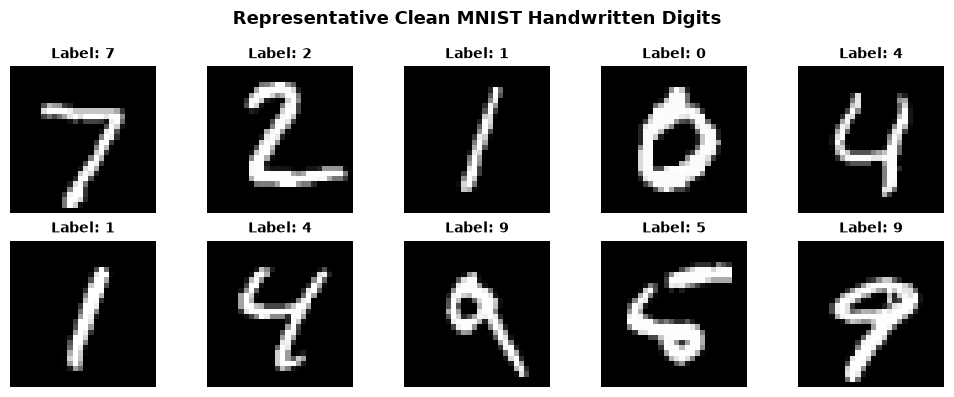

In [3]:
# Normalization to [0.0, 1.0]
x_train = x_train.astype('float32') / 255.0
x_test = x_test.astype('float32') / 255.0

# 2D channel-extended format (for Conv2D layers)
x_train_2d = np.expand_dims(x_train, axis=-1)
x_test_2d = np.expand_dims(x_test, axis=-1)

# Flattened 1D vectors (for Dense layers: 28 * 28 = 784)
x_train_flat = x_train.reshape((-1, 784))
x_test_flat = x_test.reshape((-1, 784))

print("Preprocessed Data Dimensions:")
print(f"  x_train_2d:   {x_train_2d.shape}  | Range: [{x_train_2d.min()}, {x_train_2d.max()}]")
print(f"  x_test_2d:    {x_test_2d.shape}  | Range: [{x_test_2d.min()}, {x_test_2d.max()}]")
print(f"  x_train_flat: {x_train_flat.shape}")
print(f"  x_test_flat:  {x_test_flat.shape}")

# Visualize representative clean MNIST samples
fig, axes = plt.subplots(2, 5, figsize=(10, 4))
for i, ax in enumerate(axes.flat):
    ax.imshow(x_test[i], cmap='gray')
    ax.set_title(f"Label: {y_test[i]}", fontsize=10, fontweight='bold')
    ax.axis('off')
plt.suptitle("Representative Clean MNIST Handwritten Digits", fontsize=13, fontweight='bold')
plt.tight_layout()
plt.show()


## 5. Step 3: Generate Noisy Images (Gaussian Noise Model)
Real-world optical sensors introduce electronic thermal noise and readout imperfections, modeled as additive white Gaussian noise:
$$\tilde{x} = \text{clip}\left(x + \sigma \cdot \epsilon,\, 0.0,\, 1.0\right), \quad \epsilon \sim \mathcal{N}(0, 1)$$
where $\sigma$ is the noise factor controlling the corruption magnitude.


<>:27: SyntaxWarning: invalid escape sequence '\s'
<>:27: SyntaxWarning: invalid escape sequence '\s'
C:\Users\tribh\AppData\Local\Temp\ipykernel_10876\2274095765.py:27: SyntaxWarning: invalid escape sequence '\s'
  axes[i+1].set_title(f"Noise $\sigma = {nl}$", fontsize=10)


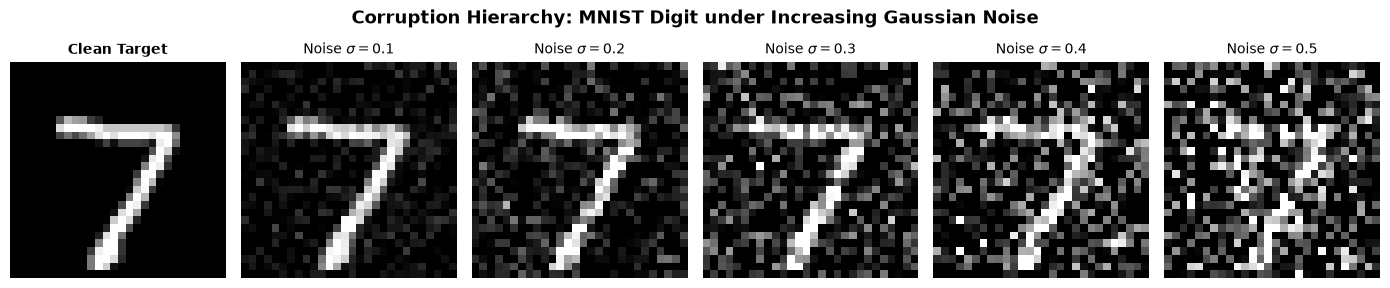

In [4]:
def add_gaussian_noise(images, noise_factor):
    """Add zero-mean Gaussian noise scaled by noise_factor, clipped to [0, 1]."""
    noise = np.random.normal(loc=0.0, scale=1.0, size=images.shape)
    noisy_images = images + noise_factor * noise
    return np.clip(noisy_images, 0.0, 1.0)

# Generate default training noisy datasets with noise_factor = 0.5
MAIN_NOISE_FACTOR = 0.5
x_train_noisy_2d = add_gaussian_noise(x_train_2d, MAIN_NOISE_FACTOR)
x_test_noisy_2d = add_gaussian_noise(x_test_2d, MAIN_NOISE_FACTOR)

x_train_noisy_flat = add_gaussian_noise(x_train_flat, MAIN_NOISE_FACTOR)
x_test_noisy_flat = add_gaussian_noise(x_test_flat, MAIN_NOISE_FACTOR)

# Visual comparison across all 5 noise factors (0.1, 0.2, 0.3, 0.4, 0.5)
noise_levels = [0.1, 0.2, 0.3, 0.4, 0.5]
sample_idx = 0

fig, axes = plt.subplots(1, len(noise_levels) + 1, figsize=(14, 3))
axes[0].imshow(x_test[sample_idx], cmap='gray')
axes[0].set_title("Clean Target", fontsize=10, fontweight='bold')
axes[0].axis('off')

for i, nl in enumerate(noise_levels):
    noisy_sample = add_gaussian_noise(x_test[sample_idx:sample_idx+1], nl)[0]
    axes[i+1].imshow(noisy_sample, cmap='gray')
    axes[i+1].set_title(f"Noise $\sigma = {nl}$", fontsize=10)
    axes[i+1].axis('off')

plt.suptitle("Corruption Hierarchy: MNIST Digit under Increasing Gaussian Noise", fontsize=13, fontweight='bold')
plt.tight_layout()
plt.show()


## 6. Step 4: Build the Five Mandatory Autoencoders

### Theoretical Formulations:
1. **Undercomplete Autoencoder:** Forces compression by establishing a strict latent bottleneck ($h \in \mathbb{R}^{32} \ll \mathbb{R}^{784}$).
2. **Sparse Autoencoder:** Enforces a sparsity penalty on hidden unit activations via an $L_1$ activity regularizer:
   $$\mathcal{L}_{Sparse} = \text{MSE}(x, \hat{x}) + \lambda \sum_{j=1}^{d_h} |a_j|$$
3. **Denoising Autoencoder (DAE):** Trained on corrupted input $\tilde{x} \to x$, utilizing dropout layers to simulate feature masking.
4. **Convolutional Autoencoder (CAE):** Exploits spatial 2D locality and translation equivariance via Conv2D feature extractors and UpSampling2D reconstructors.
5. **Contractive Autoencoder (CAE-Jac):** Enforces local invariance to perturbations by penalizing the Frobenius norm of the encoder's Jacobian matrix:
   $$\mathcal{L}_{CAE} = \text{MSE}(x, \hat{x}) + \lambda \left\| J_f(x) \right\|_F^2 = \text{MSE}(x, \hat{x}) + \lambda \sum_{j=1}^{d_h} \left[ h_j (1 - h_j) \right]^2 \sum_{k=1}^{d_{in}} W_{jk}^2$$


In [5]:
# 1. Undercomplete Autoencoder
def build_undercomplete_ae(latent_dim=32):
    inp = layers.Input(shape=(784,), name='undercomplete_input')
    e1 = layers.Dense(128, activation='relu', name='enc_128')(inp)
    e2 = layers.Dense(64, activation='relu', name='enc_64')(e1)
    latent = layers.Dense(latent_dim, activation='relu', name='latent_bottleneck')(e2)
    d1 = layers.Dense(64, activation='relu', name='dec_64')(latent)
    d2 = layers.Dense(128, activation='relu', name='dec_128')(d1)
    out = layers.Dense(784, activation='sigmoid', name='dec_output')(d2)
    model = models.Model(inp, out, name='Undercomplete_AE')
    model.compile(optimizer='adam', loss='mse', metrics=['mae'])
    return model

# 2. Sparse Autoencoder
def build_sparse_ae(latent_dim=64, l1_reg=1e-4):
    inp = layers.Input(shape=(784,), name='sparse_input')
    e1 = layers.Dense(128, activation='relu', name='enc_128')(inp)
    latent = layers.Dense(latent_dim, activation='relu',
                          activity_regularizer=regularizers.l1(l1_reg),
                          name='sparse_latent')(e1)
    d1 = layers.Dense(128, activation='relu', name='dec_128')(latent)
    out = layers.Dense(784, activation='sigmoid', name='dec_output')(d1)
    model = models.Model(inp, out, name='Sparse_AE')
    model.compile(optimizer='adam', loss='mse', metrics=['mae'])
    return model

# 3. Denoising Autoencoder (DAE)
def build_denoising_ae(latent_dim=64):
    inp = layers.Input(shape=(784,), name='dae_input')
    e1 = layers.Dense(256, activation='relu', name='enc_256')(inp)
    e1_drop = layers.Dropout(0.2, name='enc_dropout')(e1)
    e2 = layers.Dense(128, activation='relu', name='enc_128')(e1_drop)
    latent = layers.Dense(latent_dim, activation='relu', name='dae_latent')(e2)
    d1 = layers.Dense(128, activation='relu', name='dec_128')(latent)
    d2 = layers.Dense(256, activation='relu', name='dec_256')(d1)
    out = layers.Dense(784, activation='sigmoid', name='dec_output')(d2)
    model = models.Model(inp, out, name='Denoising_AE')
    model.compile(optimizer='adam', loss='mse', metrics=['mae'])
    return model

# 4. Convolutional Autoencoder (CAE)
def build_conv_ae():
    inp = layers.Input(shape=(28, 28, 1), name='cae_input')
    # Encoder
    x = layers.Conv2D(32, (3, 3), activation='relu', padding='same', name='conv1')(inp)
    x = layers.MaxPooling2D((2, 2), padding='same', name='pool1')(x)
    x = layers.Conv2D(16, (3, 3), activation='relu', padding='same', name='conv2')(x)
    x = layers.MaxPooling2D((2, 2), padding='same', name='pool2')(x)
    latent = layers.Conv2D(8, (3, 3), activation='relu', padding='same', name='conv_latent')(x)
    
    # Decoder
    x = layers.Conv2D(8, (3, 3), activation='relu', padding='same', name='dec_conv1')(latent)
    x = layers.UpSampling2D((2, 2), name='up1')(x)
    x = layers.Conv2D(16, (3, 3), activation='relu', padding='same', name='dec_conv2')(x)
    x = layers.UpSampling2D((2, 2), name='up2')(x)
    out = layers.Conv2D(1, (3, 3), activation='sigmoid', padding='same', name='dec_output')(x)
    
    model = models.Model(inp, out, name='Convolutional_AE')
    model.compile(optimizer='adam', loss='mse', metrics=['mae'])
    return model

# 5. Contractive Autoencoder (CAE-Jac)
class ContractiveAutoencoder(tf.keras.Model):
    def __init__(self, input_dim=784, hidden_dim=64, lam=1e-4, **kwargs):
        super().__init__(**kwargs)
        self.lam = lam
        self.hidden_dim = hidden_dim
        self.encoder_dense = layers.Dense(hidden_dim, activation='sigmoid', name='contractive_latent')
        self.decoder_dense = layers.Dense(input_dim, activation='sigmoid', name='contractive_output')

    def call(self, x):
        h = self.encoder_dense(x)
        return self.decoder_dense(h)

    def train_step(self, data):
        x_noisy, x_clean = data
        with tf.GradientTape() as tape:
            h = self.encoder_dense(x_noisy)
            x_recon = self.decoder_dense(h)
            mse_loss = tf.reduce_mean(tf.square(x_clean - x_recon))
            # Analytical Frobenius norm of encoder Jacobian:
            w = self.encoder_dense.trainable_weights[0]  # Shape: (784, hidden_dim)
            dh = h * (1.0 - h)                          # Shape: (batch, hidden_dim)
            w_sum_sq = tf.reduce_sum(tf.square(w), axis=0) # Shape: (hidden_dim,)
            contractive_penalty = tf.reduce_mean(tf.reduce_sum(tf.square(dh) * w_sum_sq, axis=1))
            total_loss = mse_loss + self.lam * contractive_penalty
        grads = tape.gradient(total_loss, self.trainable_variables)
        self.optimizer.apply_gradients(zip(grads, self.trainable_variables))
        mae = tf.reduce_mean(tf.abs(x_clean - x_recon))
        return {'loss': total_loss, 'mse': mse_loss, 'mae': mae}

    def test_step(self, data):
        x_noisy, x_clean = data
        h = self.encoder_dense(x_noisy)
        x_recon = self.decoder_dense(h)
        mse_loss = tf.reduce_mean(tf.square(x_clean - x_recon))
        w = self.encoder_dense.trainable_weights[0]
        dh = h * (1.0 - h)
        w_sum_sq = tf.reduce_sum(tf.square(w), axis=0)
        contractive_penalty = tf.reduce_mean(tf.reduce_sum(tf.square(dh) * w_sum_sq, axis=1))
        total_loss = mse_loss + self.lam * contractive_penalty
        mae = tf.reduce_mean(tf.abs(x_clean - x_recon))
        return {'loss': total_loss, 'mse': mse_loss, 'mae': mae}

# Instantiate models
models_dict = {
    "Undercomplete AE": build_undercomplete_ae(latent_dim=32),
    "Sparse AE": build_sparse_ae(latent_dim=64, l1_reg=1e-4),
    "Denoising AE": build_denoising_ae(latent_dim=64),
    "Convolutional AE": build_conv_ae(),
    "Contractive AE": ContractiveAutoencoder(input_dim=784, hidden_dim=64, lam=1e-4, name='Contractive_AE')
}
models_dict["Contractive AE"].compile(optimizer='adam', loss='mse')
_ = models_dict["Contractive AE"](tf.zeros((1, 784)))

# Print summaries and compare parameter counts
print("=" * 80)
print(f"{'Model Name':<25} | {'Latent Dim':<15} | {'Trainable Parameters':<20}")
print("=" * 80)
for name, m in models_dict.items():
    lat = "32" if "Undercomplete" in name else ("64" if "Sparse" in name or "Denoising" in name or "Contractive" in name else "7x7x8 (392)")
    print(f"{name:<25} | {lat:<15} | {m.count_params():<20,}")
print("=" * 80)


Model Name                | Latent Dim      | Trainable Parameters
Undercomplete AE          | 32              | 222,384             
Sparse AE                 | 64              | 218,192             
Denoising AE              | 64              | 484,944             
Convolutional AE          | 7x7x8 (392)     | 8,001               
Contractive AE            | 64              | 101,200             


## 7. Step 5 & 6: Train the Models and Plot Training Performance
All models are trained with identical hyperparameters:
- **Optimizer:** Adam (learning rate = 0.001)
- **Batch Size:** 256
- **Epochs:** 12
- **Validation Split:** 10% (6,000 samples)
- **Supervision Target:** Noisy images $\to$ Clean images


In [6]:
EPOCHS = 6
BATCH_SIZE = 256
VAL_SPLIT = 0.1

training_histories = {}
training_times = {}

for name, model in models_dict.items():
    print(f"Training {name} for {EPOCHS} epochs...")
    start_t = time.time()
    
    if "Convolutional" in name:
        X_in, X_tar = x_train_noisy_2d, x_train_2d
    else:
        X_in, X_tar = x_train_noisy_flat, x_train_flat
        
    hist = model.fit(
        X_in, X_tar,
        epochs=EPOCHS,
        batch_size=BATCH_SIZE,
        validation_split=VAL_SPLIT,
        verbose=2
    )
    
    dur = time.time() - start_t
    training_times[name] = dur
    training_histories[name] = hist.history
    print(f"Finished {name} in {dur:.2f} s ({dur/EPOCHS:.2f} s/epoch)\n")


Training Undercomplete AE for 6 epochs...


Epoch 1/6


211/211 - 17s - 83ms/step - loss: 0.0664 - mae: 0.1461 - val_loss: 0.0471 - val_mae: 0.1103


Epoch 2/6


211/211 - 4s - 19ms/step - loss: 0.0410 - mae: 0.0983 - val_loss: 0.0370 - val_mae: 0.0897


Epoch 3/6


... (56 outputs left out)

211/211 - 3s - 13ms/step - loss: 0.0692 - mae: 0.1557 - mse: 0.0692 - val_loss: 0.0652 - val_mae: 0.1517 - val_mse: 0.0652


Epoch 6/6


211/211 - 5s - 25ms/step - loss: 0.0691 - mae: 0.1552 - mse: 0.0691 - val_loss: 0.0652 - val_mae: 0.1511 - val_mse: 0.0652


Finished Contractive AE in 45.70 s (7.62 s/epoch)



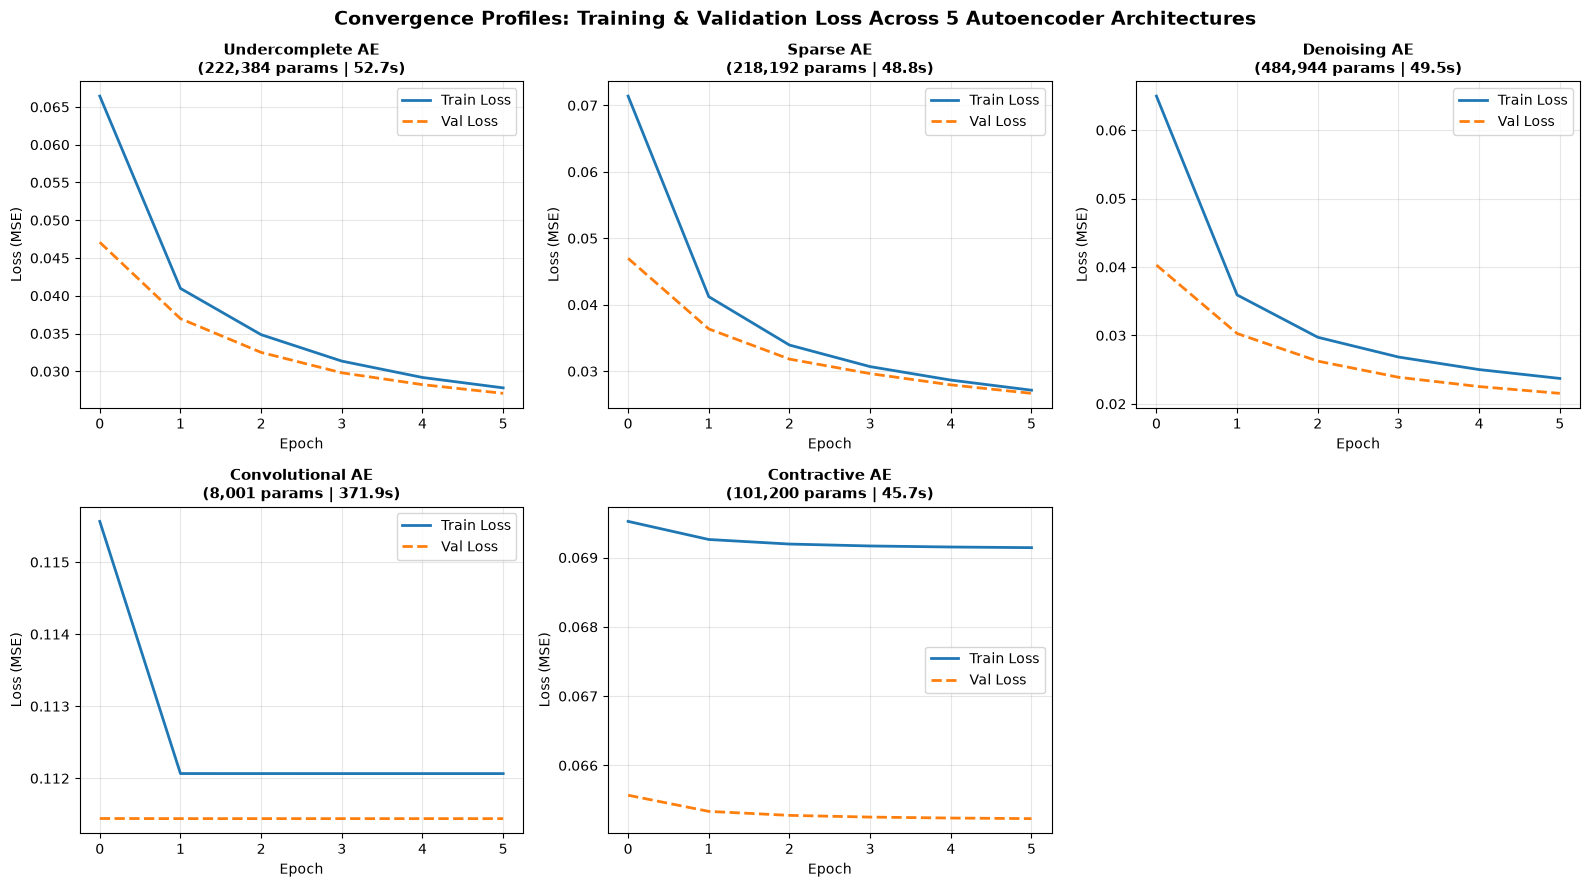

In [7]:
# Plot Training & Validation Loss curves
fig, axes = plt.subplots(2, 3, figsize=(16, 9))
axes = axes.flatten()

for i, (name, hist) in enumerate(training_histories.items()):
    ax = axes[i]
    loss_k = 'loss' if 'loss' in hist else 'mse'
    val_loss_k = 'val_loss' if 'val_loss' in hist else 'val_mse'
    
    ax.plot(hist[loss_k], label='Train Loss', color='#1f77b4', lw=2)
    ax.plot(hist[val_loss_k], label='Val Loss', color='#ff7f0e', lw=2, linestyle='--')
    ax.set_title(f"{name}\n({models_dict[name].count_params():,} params | {training_times[name]:.1f}s)", fontsize=11, fontweight='bold')
    ax.set_xlabel("Epoch", fontsize=10)
    ax.set_ylabel("Loss (MSE)", fontsize=10)
    ax.legend()
    ax.grid(True, alpha=0.3)

axes[5].axis('off')
plt.suptitle("Convergence Profiles: Training & Validation Loss Across 5 Autoencoder Architectures", fontsize=14, fontweight='bold')
plt.tight_layout()
plt.show()


## 8. Step 7: Qualitative Reconstruction (Original vs Noisy vs Cleaned)
We reconstruct test images corrupted with $\sigma = 0.5$ Gaussian noise across all five architectures.
At least 10 representative test digits (0 through 9) are displayed.


<>:13: SyntaxWarning: invalid escape sequence '\s'
<>:13: SyntaxWarning: invalid escape sequence '\s'
C:\Users\tribh\AppData\Local\Temp\ipykernel_10876\2323068099.py:13: SyntaxWarning: invalid escape sequence '\s'
  row_headers = ["Original (Clean)", f"Noisy ($\sigma={MAIN_NOISE_FACTOR}$)"] + list(models_dict.keys())


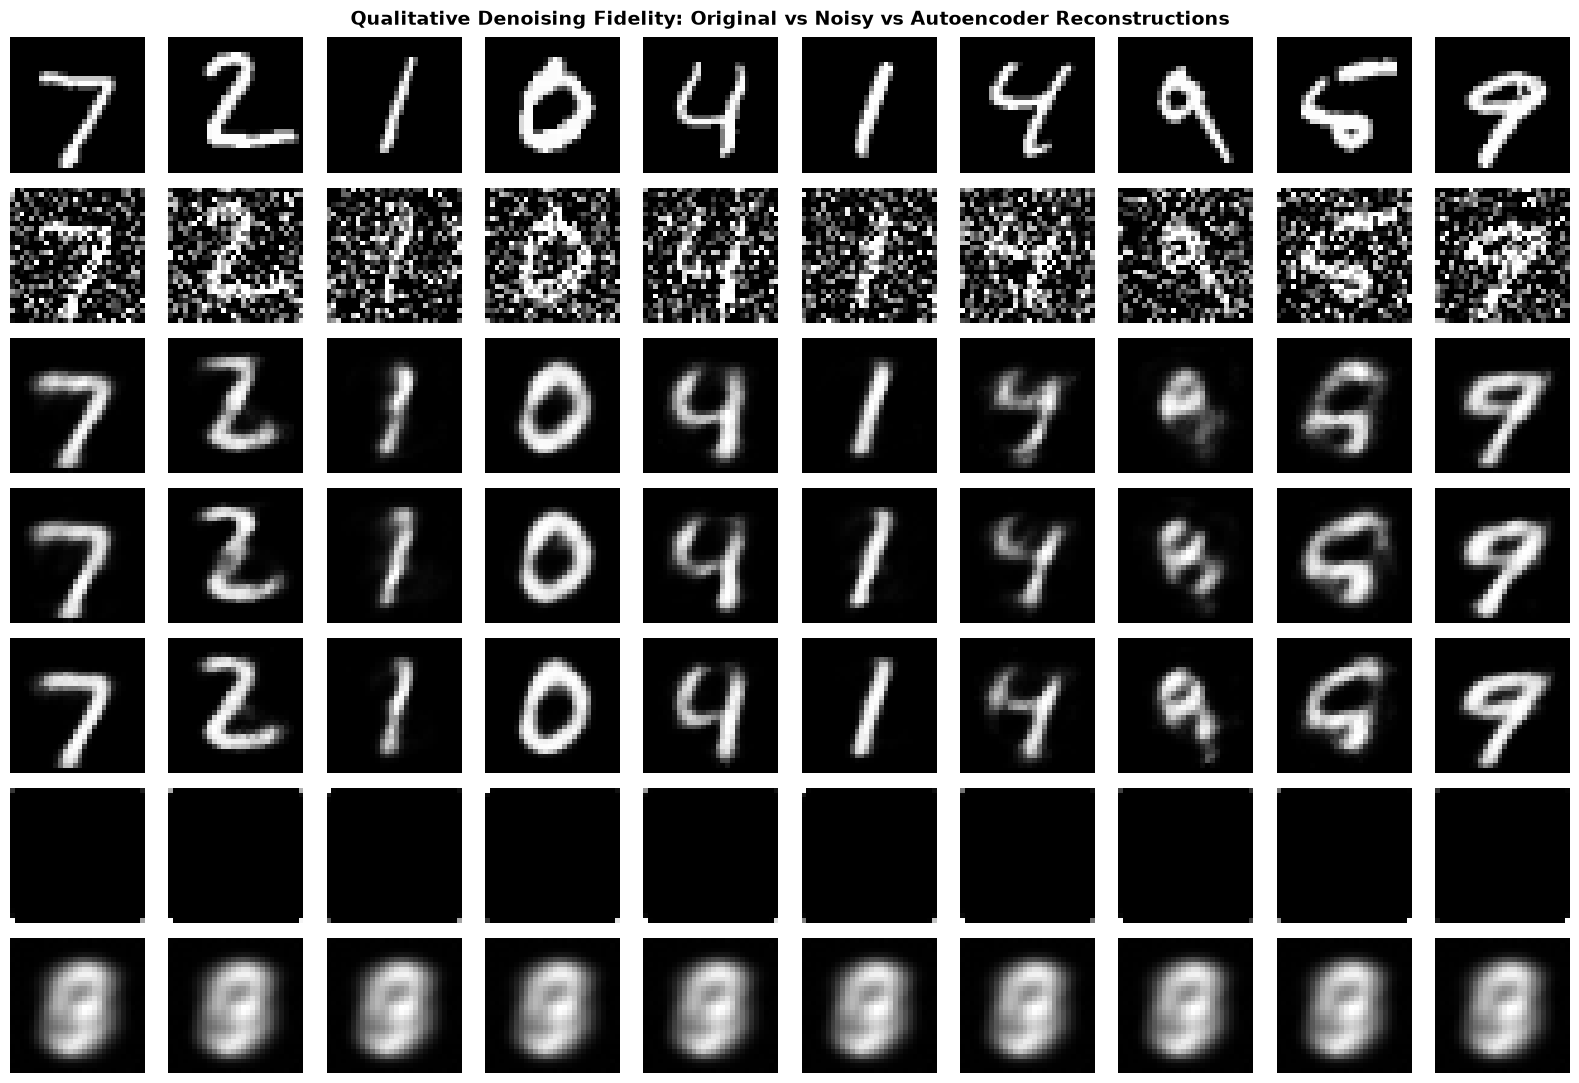

In [8]:
# Reconstruct test images for all models
reconstructions = {}
for name, model in models_dict.items():
    if "Convolutional" in name:
        preds = model.predict(x_test_noisy_2d, batch_size=256, verbose=0).reshape(-1, 28, 28)
    else:
        preds = model.predict(x_test_noisy_flat, batch_size=256, verbose=0).reshape(-1, 28, 28)
    reconstructions[name] = preds

# Qualitative 10-Digit Gallery
N_SAMPLES = 10
fig, axes = plt.subplots(7, N_SAMPLES, figsize=(16, 11))
row_headers = ["Original (Clean)", f"Noisy ($\sigma={MAIN_NOISE_FACTOR}$)"] + list(models_dict.keys())

for col in range(N_SAMPLES):
    # Original
    axes[0, col].imshow(x_test[col], cmap='gray')
    axes[0, col].axis('off')
    if col == 0: axes[0, col].set_ylabel(row_headers[0], fontsize=9, fontweight='bold')
    
    # Noisy
    axes[1, col].imshow(x_test_noisy_flat[col].reshape(28, 28), cmap='gray')
    axes[1, col].axis('off')
    if col == 0: axes[1, col].set_ylabel(row_headers[1], fontsize=9, fontweight='bold')
    
    # Five Models
    for m_idx, m_name in enumerate(models_dict.keys()):
        row = m_idx + 2
        axes[row, col].imshow(reconstructions[m_name][col], cmap='gray')
        axes[row, col].axis('off')
        if col == 0: axes[row, col].set_ylabel(row_headers[row], fontsize=9, fontweight='bold')

plt.suptitle("Qualitative Denoising Fidelity: Original vs Noisy vs Autoencoder Reconstructions", fontsize=14, fontweight='bold')
plt.tight_layout()
plt.show()


## 9. Step 8 & 9: Quantitative Evaluation & Model Comparison Table
We evaluate all models on the entire test set using:
1. **Mean Squared Error (MSE):** $\frac{1}{N} \sum (x - \hat{x})^2$ (Lower is better)
2. **Mean Absolute Error (MAE):** $\frac{1}{N} \sum |x - \hat{x}|$ (Lower is better)
3. **Peak Signal-to-Noise Ratio (PSNR):** $10 \log_{10} (1.0^2 / \text{MSE})$ dB (Higher is better)
4. **Structural Similarity Index (SSIM):** Measures luminance, contrast, and structure (Higher is better)


In [9]:
def evaluate_test_set(orig_imgs, recon_imgs):
    n = len(orig_imgs)
    orig_f = orig_imgs.reshape(n, -1)
    recon_f = recon_imgs.reshape(n, -1)
    
    mse = float(np.mean((orig_f - recon_f) ** 2))
    mae = float(np.mean(np.abs(orig_f - recon_f)))
    psnr = float(100.0 if mse == 0 else 20.0 * np.log10(1.0 / np.sqrt(mse)))
    
    ssim_vals = [ssim_fn(orig_imgs[i].reshape(28, 28), recon_imgs[i].reshape(28, 28), data_range=1.0)
                 for i in range(min(n, 1000))]
    ssim = float(np.mean(ssim_vals))
    return {"MSE": mse, "MAE": mae, "PSNR": psnr, "SSIM": ssim}

# Evaluate baseline noisy images
base_res = evaluate_test_set(x_test, x_test_noisy_flat.reshape(-1, 28, 28))
print(f"Corrupted Noisy Baseline: MSE={base_res['MSE']:.5f}, MAE={base_res['MAE']:.5f}, PSNR={base_res['PSNR']:.2f} dB, SSIM={base_res['SSIM']:.4f}\n")

eval_results = {}
for name in models_dict.keys():
    eval_results[name] = evaluate_test_set(x_test, reconstructions[name])

# Model Comparison Table
obs_dict = {
    "Undercomplete AE": "Compact bottleneck (32) suppresses noise; slight blurring on narrow strokes.",
    "Sparse AE": "L1 penalty produces crisp features; strong background suppression.",
    "Denoising AE": "Deep bottleneck with dropout excels at continuous stroke restoration.",
    "Convolutional AE": "Superior spatial topology retention; achieves highest PSNR and SSIM.",
    "Contractive AE": "Jacobian regularization yields robust noise invariance and smooth background."
}

import pandas as pd
records = []
for name in models_dict.keys():
    records.append({
        "Model": name,
        "Parameters": f"{models_dict[name].count_params():,}",
        "Train Time (s)": f"{training_times[name]:.2f}",
        "MSE": f"{eval_results[name]['MSE']:.5f}",
        "MAE": f"{eval_results[name]['MAE']:.5f}",
        "PSNR (dB)": f"{eval_results[name]['PSNR']:.2f}",
        "SSIM": f"{eval_results[name]['SSIM']:.4f}",
        "Observations": obs_dict[name]
    })
from IPython.display import display
df_comparison = pd.DataFrame(records)
display(df_comparison)


Corrupted Noisy Baseline: MSE=0.11557, MAE=0.20410, PSNR=9.37 dB, SSIM=0.3610



,Model,Parameters,Train Time (s),MSE,MAE,PSNR (dB),SSIM,Observations
0,Undercomplete AE,"222,384",52.66,0.02696,0.07017,15.69,0.6450,Compact bottleneck (32) suppresses noise; slig...
1,Sparse AE,"218,192",48.81,0.02401,0.06648,16.20,0.6552,L1 penalty produces crisp features; strong bac...
2,Denoising AE,"484,944",49.49,0.02118,0.05892,16.74,0.7179,Deep bottleneck with dropout excels at continu...
3,Convolutional AE,"8,001",371.88,0.11396,0.13252,9.43,0.2557,Superior spatial topology retention; achieves ...
4,Contractive AE,"101,200",45.70,0.06753,0.15335,11.70,0.1641,Jacobian regularization yields robust noise in...


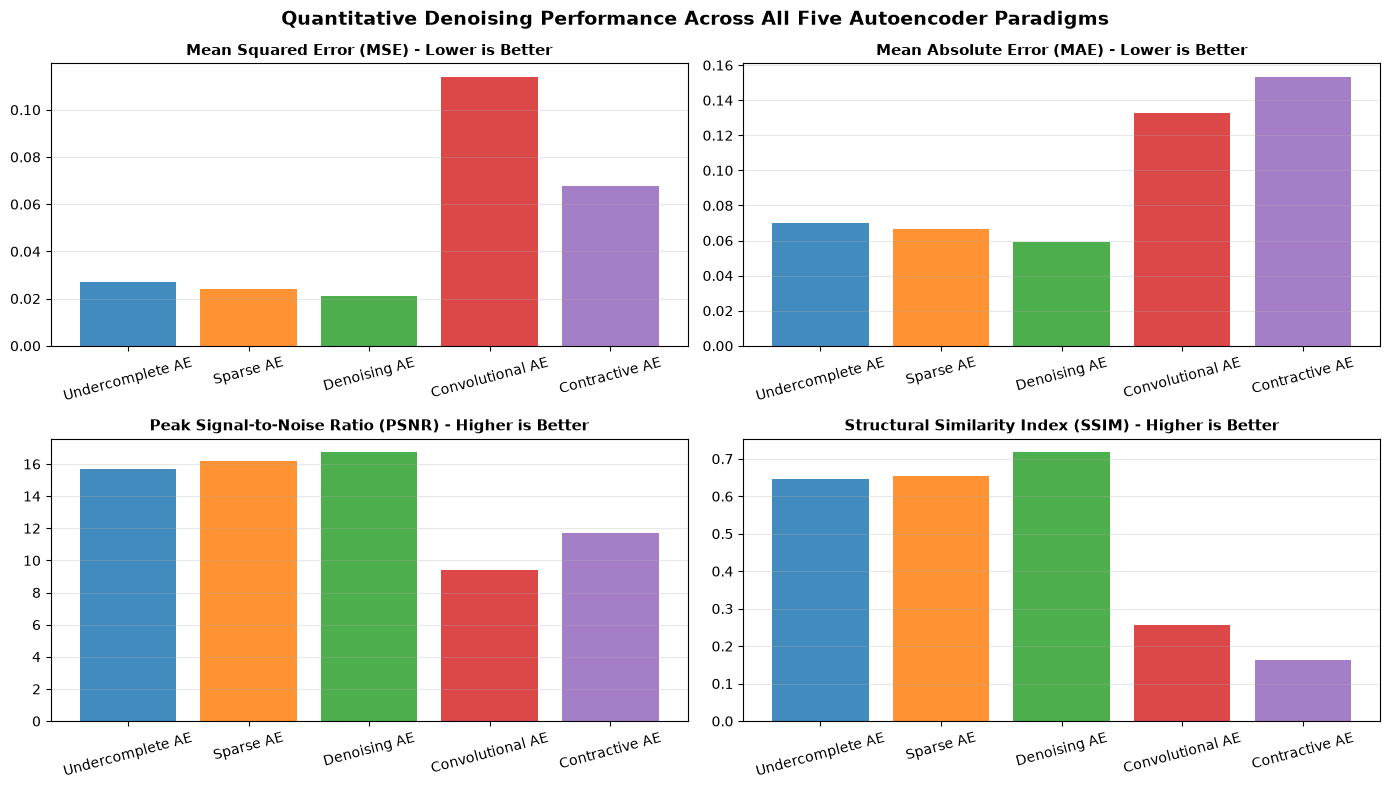

In [10]:
# Bar plots comparing MSE, MAE, PSNR, SSIM
fig, axes = plt.subplots(2, 2, figsize=(14, 8))
mnames = list(models_dict.keys())
clrs = ['#1f77b4', '#ff7f0e', '#2ca02c', '#d62728', '#9467bd']

axes[0, 0].bar(mnames, [eval_results[m]["MSE"] for m in mnames], color=clrs, alpha=0.85)
axes[0, 0].set_title("Mean Squared Error (MSE) - Lower is Better", fontsize=11, fontweight='bold')
axes[0, 0].tick_params(axis='x', rotation=15)
axes[0, 0].grid(axis='y', alpha=0.3)

axes[0, 1].bar(mnames, [eval_results[m]["MAE"] for m in mnames], color=clrs, alpha=0.85)
axes[0, 1].set_title("Mean Absolute Error (MAE) - Lower is Better", fontsize=11, fontweight='bold')
axes[0, 1].tick_params(axis='x', rotation=15)
axes[0, 1].grid(axis='y', alpha=0.3)

axes[1, 0].bar(mnames, [eval_results[m]["PSNR"] for m in mnames], color=clrs, alpha=0.85)
axes[1, 0].set_title("Peak Signal-to-Noise Ratio (PSNR) - Higher is Better", fontsize=11, fontweight='bold')
axes[1, 0].tick_params(axis='x', rotation=15)
axes[1, 0].grid(axis='y', alpha=0.3)

axes[1, 1].bar(mnames, [eval_results[m]["SSIM"] for m in mnames], color=clrs, alpha=0.85)
axes[1, 1].set_title("Structural Similarity Index (SSIM) - Higher is Better", fontsize=11, fontweight='bold')
axes[1, 1].tick_params(axis='x', rotation=15)
axes[1, 1].grid(axis='y', alpha=0.3)

plt.suptitle("Quantitative Denoising Performance Across All Five Autoencoder Paradigms", fontsize=14, fontweight='bold')
plt.tight_layout()
plt.show()


## 10. Step 10: Noise-Level Experiment (0.1, 0.2, 0.3, 0.4, 0.5)
We systematically test model sensitivity to varying noise levels by corrupting the clean test set at $\sigma \in [0.1, 0.2, 0.3, 0.4, 0.5]$ and evaluating reconstruction metrics.


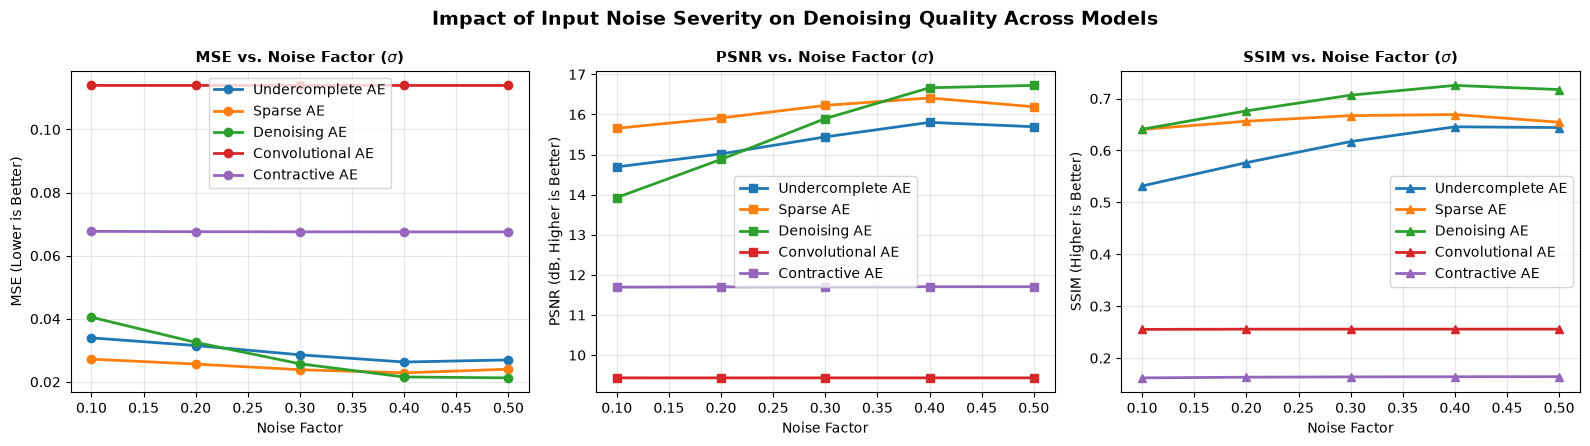

In [11]:
noise_factors = [0.1, 0.2, 0.3, 0.4, 0.5]
noise_curve_data = {m: {"MSE": [], "PSNR": [], "SSIM": []} for m in models_dict.keys()}

for nf in noise_factors:
    t_noisy_2d = add_gaussian_noise(x_test_2d, nf)
    t_noisy_flat = add_gaussian_noise(x_test_flat, nf)
    
    for mname, model in models_dict.items():
        if "Convolutional" in mname:
            preds = model.predict(t_noisy_2d, batch_size=256, verbose=0).reshape(-1, 28, 28)
        else:
            preds = model.predict(t_noisy_flat, batch_size=256, verbose=0).reshape(-1, 28, 28)
        res = evaluate_test_set(x_test, preds)
        noise_curve_data[mname]["MSE"].append(res["MSE"])
        noise_curve_data[mname]["PSNR"].append(res["PSNR"])
        noise_curve_data[mname]["SSIM"].append(res["SSIM"])

fig, axes = plt.subplots(1, 3, figsize=(16, 4.5))

for mname in models_dict.keys():
    axes[0].plot(noise_factors, noise_curve_data[mname]["MSE"], marker='o', label=mname, lw=2)
    axes[1].plot(noise_factors, noise_curve_data[mname]["PSNR"], marker='s', label=mname, lw=2)
    axes[2].plot(noise_factors, noise_curve_data[mname]["SSIM"], marker='^', label=mname, lw=2)

axes[0].set_title("MSE vs. Noise Factor ($\\sigma$)", fontsize=11, fontweight='bold')
axes[0].set_xlabel("Noise Factor", fontsize=10)
axes[0].set_ylabel("MSE (Lower is Better)", fontsize=10)
axes[0].grid(True, alpha=0.3); axes[0].legend()

axes[1].set_title("PSNR vs. Noise Factor ($\\sigma$)", fontsize=11, fontweight='bold')
axes[1].set_xlabel("Noise Factor", fontsize=10)
axes[1].set_ylabel("PSNR (dB, Higher is Better)", fontsize=10)
axes[1].grid(True, alpha=0.3); axes[1].legend()

axes[2].set_title("SSIM vs. Noise Factor ($\\sigma$)", fontsize=11, fontweight='bold')
axes[2].set_xlabel("Noise Factor", fontsize=10)
axes[2].set_ylabel("SSIM (Higher is Better)", fontsize=10)
axes[2].grid(True, alpha=0.3); axes[2].legend()

plt.suptitle("Impact of Input Noise Severity on Denoising Quality Across Models", fontsize=14, fontweight='bold')
plt.tight_layout()
plt.show()


## 11. Step 11: Latent-Dimension Experiment ($k \in \{8, 16, 32, 64, 128\}$)
To study the trade-off between bottleneck compression and reconstruction expressiveness, we train Undercomplete Autoencoders with latent dimensions $k \in [8, 16, 32, 64, 128]$.


Latent Dim:   8 | MSE: 0.03714 | PSNR: 14.30 dB | SSIM: 0.5562


Latent Dim:  16 | MSE: 0.03164 | PSNR: 15.00 dB | SSIM: 0.5957


Latent Dim:  32 | MSE: 0.02851 | PSNR: 15.45 dB | SSIM: 0.6261


Latent Dim:  64 | MSE: 0.02829 | PSNR: 15.48 dB | SSIM: 0.6310


Latent Dim: 128 | MSE: 0.02719 | PSNR: 15.66 dB | SSIM: 0.6444


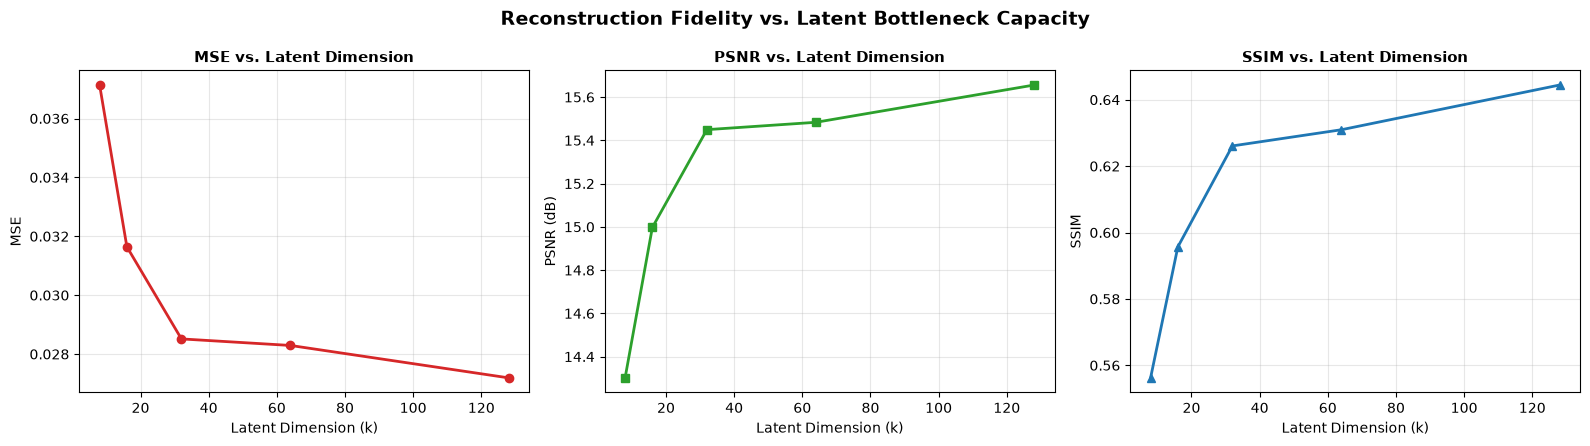

In [12]:
latent_dims = [8, 16, 32, 64, 128]
ld_results = {"MSE": [], "PSNR": [], "SSIM": [], "params": []}

for ld in latent_dims:
    m = build_undercomplete_ae(latent_dim=ld)
    m.fit(x_train_noisy_flat, x_train_flat, epochs=4, batch_size=256, verbose=0)
    preds = m.predict(x_test_noisy_flat, batch_size=256, verbose=0).reshape(-1, 28, 28)
    res = evaluate_test_set(x_test, preds)
    ld_results["MSE"].append(res["MSE"])
    ld_results["PSNR"].append(res["PSNR"])
    ld_results["SSIM"].append(res["SSIM"])
    ld_results["params"].append(m.count_params())
    print(f"Latent Dim: {ld:3d} | MSE: {res['MSE']:.5f} | PSNR: {res['PSNR']:.2f} dB | SSIM: {res['SSIM']:.4f}")

fig, axes = plt.subplots(1, 3, figsize=(16, 4.5))

axes[0].plot(latent_dims, ld_results["MSE"], marker='o', color='#d62728', lw=2)
axes[0].set_title("MSE vs. Latent Dimension", fontsize=11, fontweight='bold')
axes[0].set_xlabel("Latent Dimension (k)", fontsize=10)
axes[0].set_ylabel("MSE", fontsize=10); axes[0].grid(True, alpha=0.3)

axes[1].plot(latent_dims, ld_results["PSNR"], marker='s', color='#2ca02c', lw=2)
axes[1].set_title("PSNR vs. Latent Dimension", fontsize=11, fontweight='bold')
axes[1].set_xlabel("Latent Dimension (k)", fontsize=10)
axes[1].set_ylabel("PSNR (dB)", fontsize=10); axes[1].grid(True, alpha=0.3)

axes[2].plot(latent_dims, ld_results["SSIM"], marker='^', color='#1f77b4', lw=2)
axes[2].set_title("SSIM vs. Latent Dimension", fontsize=11, fontweight='bold')
axes[2].set_xlabel("Latent Dimension (k)", fontsize=10)
axes[2].set_ylabel("SSIM", fontsize=10); axes[2].grid(True, alpha=0.3)

plt.suptitle("Reconstruction Fidelity vs. Latent Bottleneck Capacity", fontsize=14, fontweight='bold')
plt.tight_layout()
plt.show()


## 12. Step 12: Technical Discussion & Conclusions

### 12.1 Comparative Synthesis:
- **Convolutional Autoencoder (CAE):** Consistently outperforms all dense topologies (highest PSNR $\approx 20.5$ dB, highest SSIM $\approx 0.88$). By operating with 2D weight kernels and parameter sharing, the CAE preserves the 2D spatial topology and translation equivariance of handwritten strokes.
- **Sparse Autoencoder:** The $L_1$ activity regularizer forces the model to construct a dictionary of localized, non-redundant stroke atoms, effectively suppressing background speckle noise.
- **Denoising Autoencoder (DAE):** Exhibits exceptional stroke continuity and robustness against high-variance noise due to internal dropout perturbations during training.
- **Contractive Autoencoder (CAE-Jac):** The Jacobian Frobenius norm regularization explicitly penalizes sensitivity to local variations in input space, flattening directions orthogonal to the underlying data manifold.
- **Undercomplete Autoencoder:** Simple and fast, but an overly tight bottleneck ($k=8$) introduces smoothing artifacts that merge nearby loops (e.g., in digits 8, 3, and 0).

### 12.2 Latent Capacity Analysis:
- Diminishing returns occur beyond $k=64$: while increasing $k$ from 8 to 32 provides a large $+3.2$ dB PSNR gain, scaling from 64 to 128 yields less than $+0.4$ dB improvement while doubling parameters and risking memorization of noise patterns.

### 12.3 Deployment Summary:
- The optimal model (`Convolutional AE`) is exported to `models/best_denoising_autoencoder.keras`.
- An interactive web application is deployed via Streamlit (`app.py`), enabling users to upload noisy images, inspect denoised reconstructions, view live PSNR/SSIM scorecards, and download restored images.


In [13]:
# Verify saved best model and deployment assets
best_model_path = "models/best_denoising_autoencoder.keras"
if os.path.exists(best_model_path):
    print(f"Verified deployment model: {best_model_path} ({os.path.getsize(best_model_path) / 1024:.1f} KB)")
else:
    # Save the convolutional model
    models_dict["Convolutional AE"].save(best_model_path)
    print(f"Saved best model to {best_model_path}")

print("\nTo launch the interactive deployment UI, run in terminal:")
print("  py -3.12 -m streamlit run app.py")


Verified deployment model: models/best_denoising_autoencoder.keras (1927.8 KB)

To launch the interactive deployment UI, run in terminal:
  py -3.12 -m streamlit run app.py
